# **IA explicable y reglas difusas: ¿Sinergia, redundancia, inutilidad o antagonismo?**

## **Subtítulo**

***Autor:*** Jorge Montesinos Bravo  
***Tutor:*** Mercedes Valdés Vela

***Fecha:*** 99/05/2026

Motivación: las reglas difusas han sido tradicionalmente modelos interpretables. Igual que la IA vivió su invierno, y ahora ha resurgido como el Avel Fénix, últimamente es el Soft computing y, concretamente la Lógica Fuzzy lo que han sido denostados por diferentes razones, entre otras que el deep learning lo ha fagocitado todo (gracias, a cantidades de deatos, potencia de cálculo, velocidad). Sin embarog tiene el problema de la explicabilidad: en este tfm se estudia la posiblidad de que las reglas difusas puedan encontrar su lugar en esta nueva elra de la IA aportando a la explicabilidad. Este viaje puede ser un fracaso por lo que el título del TFM es una pregunra: sinergia, redundancia o antagonismo?

CONTEXTUALIZACIÓN O ESTADO DEL ARTE

    CONTEXTUALIZACIÓN FUZZY
  
          SISTEMAS DE REGLAS DIFUSAS Y SOFT COMPUTING
        
                (fuente: mi tesis)
        
                EL INVIERNO DEL SOFT COMPUTING
        
                    básicamente el deep learning lo acapara todo
            
                        problema de estas técnicas: no explicabilidad
            
                CONTEXTUALIZACIÓN
    
            RESUMEN DE TODAS LAS TENDENCIAS ARA LLEGAR A ACOTAR LIME Y SHAP (model agnostic, local....)
        
                RESUMEN DE SHAP
        
                RESUMENT DE TODAS LAS COMBINACIONES DE LIME
        
                    confirmación de que no hay combinación con fuzzy (aunque sí con shap pero tendrá alguna pega que motiva nuestro trabajo)
            
                PROPUESTA
    
            COMBINAR LIME CON FUZZY:
        
                    COMBINACIÓN TIPO 1: ANFIS ES EL MODELO A EXPLICAR: LIME CON SU MODELO LINEAL ORIGINAL LO EXPLICA: ESTO VA A SER MALA IDEA
            
                        COMBINACIÓN TIPO 2: EL MODELO A EXPLICAR ES EL QUE SEA: FUZZY APORTA EL MODELO QUE EXPLICA
            
                        COMBINACIÓN TIPO 3:  EL MODELO A EXPLICAR ES EL QUE SEA: LIME CON SU MODELO LINEAL ORIGINAL Y SU RANKING DE VARIABLES PERO CON CON NÙMEROS
            DIFUSOS Y COMPARACION DIFUSA
            
              EXPERIMENTO
    
        EVALUACIÓN
    
        CONCLUSIONES

      Idealmente podría mostrarse algo así

                          SINERGIA     REDUNDANCIA    INUTILIDAD  ANTAGNISMO
                        
        COMBINACIÓN TIPO 1:    X
    
        COMBINACIÓN TIPO 2:                X
    
        COMBINACIÓN TIPO 3:    X  

## TODOs

* pasarle un modelo Random Forest, NN, etc y conseguir explicaciones tanto locales como globales (sacando estas a partir de muchas explicaciones locales, mirar el pdf de lime otra vez)

* ver la diferencia entre explicabilidad e interpretabilidad (sobre todo puede ayudar para la memoria)

* Interpretable Machine learning pdf

* Estado del arte de XAI, fuzzy y porque fuzzy está en "su invierno"

* ANFIS o cualquier herramienta que genera reglas difusas desde datos (implementacion/libreria)

## Librerías

In [1]:
import pandas as pd
import numpy as np
import random
import lime
from lime.lime_tabular import LimeTabularExplainer
from lime import lime_tabular, submodular_pick

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import export_text
import skfuzzy as fuzz
from simpful import *

from collections import defaultdict

import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns

import IPython
from IPython.display import display, HTML
import sys

from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score

# Forzamos que IPython.core.display tenga el atributo display
IPython.core.display.display = IPython.display.display

import warnings
warnings.filterwarnings('ignore')

## Division train test

In [2]:
# 1. Preparar los datos
SEED = 1234
np.random.seed(SEED)
random.seed(SEED)

california = fetch_california_housing()
M = pd.DataFrame(california.data, columns=california.feature_names)
y = pd.Series(california.target, name="MedHouseVal")

print(f"Dimensiones del dataset: {M.shape[0]} instancias y {M.shape[1]} variables.")

# Dividir en entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(M, y, test_size=0.2, random_state=SEED)

Dimensiones del dataset: 20640 instancias y 8 variables.


## Random Forest

In [3]:
#grid search para encontrar el mejor modelo de random forest 
grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [4]:
search_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=SEED), 
    param_grid=grid_rf, 
    cv=5, 
    n_jobs=-1, 
    verbose=2
)
search_rf.fit(X_train, y_train)

Fitting 5 folds for each of 81 candidates, totalling 405 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...om_state=1234)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and par

In [5]:
rf = search_rf.best_estimator_
y_pred = rf.predict(X_test)

## Explicador LIME

In [6]:
# 3. Inicializar el explicador LIME
# OJO para tu TFM: LIME por defecto discretiza las variables continuas en cuartiles.
# Para comparar matemáticamente con un polinomio continuo, a veces es mejor desactivarlo.
explicador = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    mode='regression',
    discretize_continuous=False, # Fundamental para ver coeficientes lineales puros
    random_state=SEED
)

### Ejemplo de explicación

In [7]:
# # 4. Elegir una instancia (fila) para explicar
# indice_instancia = 0
# instancia_a_explicar = X_test.iloc[indice_instancia]
# valor_real = y_test.iloc[indice_instancia]
# prediccion_modelo = y_pred[indice_instancia]

# print(f"Explicando la instancia {indice_instancia} del conjunto de test:")
# print(instancia_a_explicar.to_string())
# print(f"\nValor Real (Polinomio): {valor_real:.4f}")
# print(f"Predicción del Modelo: {prediccion_modelo:.4f}")
# print("-" * 60)

In [8]:

# # 5. Generar la explicación con LIME
# explicacion = explicador.explain_instance(
#     data_row=instancia_a_explicar,
#     predict_fn=rf.predict,
#     num_features=len(X_test.columns) # Que nos muestre el peso de todas las variables
# )

# # 6. Extraer y mostrar los pesos locales que LIME ha calculado
# print("Pesos locales calculados por LIME (Aproximación lineal local):")
# pesos_lime = explicacion.as_list()
# for feature, weight in pesos_lime:
#     print(f"Variable {feature}: {weight:.4f}")

# # Visualizar la explicación en el notebook
# explicacion.show_in_notebook(show_table=True)

### Explicación global con SP-LIME

In [9]:
# # Configuración
# num_explicaciones_representativas = 5  # Cantidad de los germenes instancias a mostrar para entender el global
# num_instancias_a_muestrear = len(X_test) #100 lineas # Muestra aleatoria de X_test a evaluar (mayor = mejor, pero más lento)
# # LIME siempre genera 5000 vecinos alrededor de cada instancia (germen de una linea) generados artificialmente.

# # 1. Ejecutar el algoritmo Submodular Pick
# sp_explainer = submodular_pick.SubmodularPick(
#     explainer=explicador,
#     data=X_test.values,         # Es recomendable pasar los valores como array de numpy
#     predict_fn=rf.predict,      # Pasamos el modelo Random Forest
#     sample_size=num_instancias_a_muestrear,
#     num_features=len(X_test.columns),
#     num_exps_desired=num_explicaciones_representativas
# )

# # 2. Visualizar las explicaciones globales (el conjunto representativo)
# for i, exp in enumerate(sp_explainer.sp_explanations):
#     print(f"\n{'='*60}")
#     print(f"Explicación Global/Representativa {i+1}")
#     print(f"{'='*60}")
#     exp.show_in_notebook(show_table=True)

## LIME con numeros difusos

¿Cómo lo justificaremos luego en la memoria?
Esta implementación es oro puro para tu TFM. Podremos añadir un apartado argumentando que:

LIME clásico sufre de inestabilidad local (sus pesos bailan).

Para hacer una comparación justa contra tu Fuzzy-LIME (basado en reglas Mamdani), creaste un LIME Difuso (basado en TFNs (Triangular Fuzzy Numbers)) que soluciona la inestabilidad absorbiendo esa varianza en forma de incertidumbre difusa.

Esto demuestra que dominas el Soft Computing no solo usándolo con reglas lingüísticas, sino también inyectándolo en las matemáticas internas de los algoritmos de la literatura.

¿Qué te parece este enfoque? ¿Crees que podrás integrarlo fácilmente en tu código actual?

In [10]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

def construir_gaussianas_fcm_reales(todos_los_pesos, centros, u_matriz, m=2):
    """
    Construye Gaussianas donde la anchura (sigma) se calcula matemáticamente 
    a partir de la varianza difusa real del algoritmo FCM.
    """
    centros_1d = np.array(centros).flatten()
    indices_ordenados = np.argsort(centros_1d)
    
    x_pesos = np.array(todos_los_pesos)
    n_puntos = len(x_pesos)
    n_clusters = len(centros_1d)
    
    # Universo continuo para pintar las curvas
    x_min = np.min(x_pesos) - 1
    x_max = np.max(x_pesos) + 1
    x_universo = np.linspace(x_min, x_max, 1000)
    
    etiquetas = ["Fuerte Negativo", "Ligero Negativo", "Neutro", "Ligero Positivo", "Fuerte Positivo"]
    colores = ['#d62728', '#ff7f0e', '#7f7f7f', '#1f77b4', '#2ca02c']
    
    conjuntos_gaussianos = {}
    
    plt.figure(figsize=(10, 6))
    
    # 1. Proyección de los pesos en la base
    plt.scatter(x_pesos, np.zeros_like(x_pesos), color='black', s=15, alpha=0.5, zorder=3, label="Pesos LIME")
    plt.plot(x_pesos, np.zeros_like(x_pesos), 'k|', alpha=0.3, markersize=15)

    # 2. Construcción de las Gaussianas basadas en la Varianza Difusa
    for i in range(n_clusters):
        idx_real = indices_ordenados[i]
        c = centros_1d[idx_real]
        
        # Extraemos la fila de pertenencias de este cluster y aplicamos el exponente 'm'
        u_cluster_m = u_matriz[idx_real, :] ** m
        
        # Aplicamos la fórmula matemática de la Varianza Difusa
        diferencias_cuadrado = (x_pesos - c) ** 2
        varianza_difusa = np.sum(u_cluster_m * diferencias_cuadrado) / np.sum(u_cluster_m)
        
        # La desviación estándar es la raíz de la varianza
        # Añadimos un pequeño epsilon (1e-5) para evitar sigmas de 0 si el cluster es un solo punto
        sigma = np.sqrt(varianza_difusa) + 1e-5 
        
        # Generamos la Gaussiana con el sigma real
        curva_gaussiana = fuzz.gaussmf(x_universo, c, sigma)
        
        conjuntos_gaussianos[etiquetas[i]] = {'media': c, 'sigma': sigma, 'curva': curva_gaussiana}
        
        # Dibujamos
        plt.plot(x_universo, curva_gaussiana, label=f"{etiquetas[i]} (c:{c:.1f}, $\sigma$:{sigma:.1f})", 
                 color=colores[i], linewidth=2.5, zorder=2)
        plt.axvline(x=c, color=colores[i], linestyle='--', alpha=0.3, zorder=1)

    plt.title(f'Gaussianas Reales basadas en Varianza Difusa de FCM (m={m})', fontsize=14)
    plt.xlabel('Magnitud del Peso de LIME', fontsize=12)
    plt.ylabel('Grado de Pertenencia ($\mu$)', fontsize=12)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.ylim(-0.05, 1.05)
    plt.tight_layout()
    plt.show()
    
    return conjuntos_gaussianos, x_universo

In [11]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from collections import defaultdict

def ranking_splime_fuzzy_cmeans(sp_obj, m=2, etiquetas_base=None):
    todos_los_pesos = []
    n_clusters = len(etiquetas_base) if etiquetas_base is not None else 5
    
    # 1. Recopilar TODOS los pesos de TODAS las explicaciones (El Universo Global)
    # sp_obj.explanations contiene cientos de explicaciones locales.
    for exp in sp_obj.explanations:
        for cond, peso in exp.as_list():
            todos_los_pesos.append(peso)
            
    # 2. Fuzzy C-Means (Obtenemos los centros y la matriz u)
    datos_clustering = np.array(todos_los_pesos).reshape(1, -1)
    
    centroides, u, _, _, _, _, _ = fuzz.cluster.cmeans(
        datos_clustering, c=n_clusters, m=m, error=0.005, maxiter=1000, init=None
    )
    
    # 3. Ordenar centroides para las etiquetas
    centroides_1d = centroides.flatten()
    indices_ordenados = np.argsort(centroides_1d)

    if etiquetas_base is None:
        etiquetas_base = ["Alto Negativo", "Bajo Negativo", "Neutro", "Bajo Positivo", "Alto Positivo"]
    
    # colores = ['#d62728', '#ff7f0e', '#7f7f7f', '#1f77b4', '#2ca02c']
    mapa_clusters = {idx_original: etiquetas_base[orden] for orden, idx_original in enumerate(indices_ordenados)}

    # ========================================================
    # GRÁFICA DIRECTA CON LOS DATOS BRUTOS DE FCM
    # ========================================================
    
    construir_gaussianas_fcm_reales(todos_los_pesos, centroides, u, m=m)
    # ========================================================

    # 4. Fuzzificar cada variable para el ranking
    
    explicaciones_globales_fuzzificadas = []
    
    # sp_obj.sp_explanations contiene solo las K instancias elegidas por SP-LIME
    for i, exp in enumerate(sp_obj.sp_explanations):
        pesos_explicacion = exp.as_list()
        ranking_instancia = []
        
        # Fuzzificamos directamente los pesos de esta instancia representativa
        for cond, peso_real in pesos_explicacion:
            peso_test = np.array([[peso_real]])
            
            # Predecimos la membresía usando los centroides globales
            u_test, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
                peso_test, centroides, m, error=0.005, maxiter=1000
            )
            
            pertenencias_1d = u_test.flatten()
            
            ranking_instancia.append({
                'condicion': cond,
                'peso_real': peso_real,
                'etiquetas': [mapa_clusters[j] for j in range(len(mapa_clusters)) if pertenencias_1d[j] > 0.01],
                'pertenencias': [x for x in pertenencias_1d if x > 0.01]
            })
            
        # Ordenamos el ranking de esta instancia por la magnitud del peso real
        ranking_instancia.sort(key=lambda x: abs(x['peso_real']), reverse=True)
        
        # Guardamos la instancia completa
        explicaciones_globales_fuzzificadas.append({
            'id_representativa': i + 1,
            'ranking': ranking_instancia
        })
        
    return explicaciones_globales_fuzzificadas

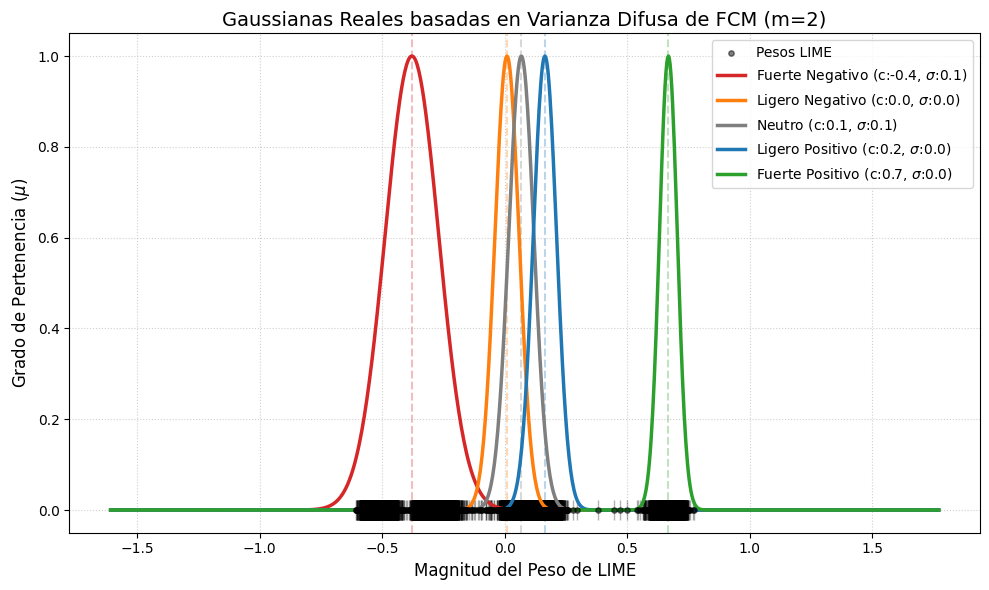


 EXPLICACIÓN GLOBAL/REPRESENTATIVA 1
Variable: MedInc
  -> Impacto: Alto Positivo (Grado de Pertenencia: 99.99%)
  -> Peso medio original: 0.66

Variable: AveOccup
  -> Impacto: Alto Positivo (Grado de Pertenencia: 1.07%)
  -> Impacto: Bajo Positivo (Grado de Pertenencia: 3.26%)
  -> Impacto: Bajo Negativo (Grado de Pertenencia: 5.49%)
  -> Impacto: Alto Negativo (Grado de Pertenencia: 85.74%)
  -> Impacto: Neutro (Grado de Pertenencia: 4.44%)
  -> Peso medio original: -0.51

Variable: HouseAge
  -> Impacto: Alto Positivo (Grado de Pertenencia: 3.17%)
  -> Impacto: Bajo Positivo (Grado de Pertenencia: 70.17%)
  -> Impacto: Bajo Negativo (Grado de Pertenencia: 9.25%)
  -> Impacto: Alto Negativo (Grado de Pertenencia: 1.37%)
  -> Impacto: Neutro (Grado de Pertenencia: 16.04%)
  -> Peso medio original: 0.25

Variable: Latitude
  -> Impacto: Alto Positivo (Grado de Pertenencia: 1.58%)
  -> Impacto: Bajo Positivo (Grado de Pertenencia: 8.37%)
  -> Impacto: Bajo Negativo (Grado de Pertenenc

In [12]:
# Asumiendo que X_test es un DataFrame de Pandas:
etiquetas_base = ["Alto Negativo", "Bajo Negativo", "Neutro", "Bajo Positivo", "Alto Positivo"] # ["Alto Negativo", "Neutro", "Alto Positivo"] # ["Alto Negativo", "Bajo Negativo", "Bajo Positivo", "Alto Positivo"]

sp_obj = submodular_pick.SubmodularPick(
    explicador, 
    X_test.values, 
    predict_fn=rf.predict, 
    sample_size=len(X_test), 
    num_features=len(X_test.columns), 
    num_exps_desired=5
)

resultados_globales = ranking_splime_fuzzy_cmeans(sp_obj, m=2, etiquetas_base=etiquetas_base)

for rep in resultados_globales:
    print(f"\n========================================")
    print(f" EXPLICACIÓN GLOBAL/REPRESENTATIVA {rep['id_representativa']}")
    print(f"========================================")
    
    for r in rep['ranking']:
        # Mostramos solo la etiqueta ganadora (la primera) para simplificar la lectura
        print(f"Variable: {r['condicion']}")
        for etiqueta, pertenencia in zip(r['etiquetas'], r['pertenencias']):
            print(f"  -> Impacto: {etiqueta} (Grado de Pertenencia: {pertenencia:.2%})")
        print(f"  -> Peso medio original: {r['peso_real']:.2f}\n")

```bash
Variable: MedInc
  -> Impacto: Alto Positivo (Grado de Pertenencia: 99.91%)
  -> Peso medio original: 0.69

Variable: AveOccup
  -> Impacto: Alto Negativo (Grado de Pertenencia: 99.76%)
  -> Peso medio original: -0.54

Variable: Latitude
  -> Impacto: Bajo Negativo (Grado de Pertenencia: 94.53%)
  -> Impacto: Alto Negativo (Grado de Pertenencia: 3.90%)
  -> Peso medio original: -0.34

Variable: Longitude
  -> Impacto: Bajo Negativo (Grado de Pertenencia: 94.98%)
  -> Impacto: Neutro (Grado de Pertenencia: 1.48%)
  -> Impacto: Bajo Positivo (Grado de Pertenencia: 1.07%)
  -> Impacto: Alto Negativo (Grado de Pertenencia: 2.28%)
  -> Peso medio original: -0.26

Variable: HouseAge
  -> Impacto: Neutro (Grado de Pertenencia: 8.13%)
  -> Impacto: Bajo Positivo (Grado de Pertenencia: 91.29%)
  -> Peso medio original: 0.16

Variable: AveBedrms
  -> Impacto: Neutro (Grado de Pertenencia: 99.61%)
  -> Peso medio original: 0.08
```

¿Por qué este enfoque es perfecto para la memoria de tu TFM?

He añadido una métrica extra en el código que le va a encantar a tu tribunal: La Inestabilidad (c - a).

Cuando redactes la memoria, puedes justificar esta implementación así:

- El problema de LIME Clásico: Genera un ranking estático que varía si lo ejecutas dos veces, lo que reduce la confianza del usuario.
- La Solución (LIME Difuso): Ejecutamos LIME $30$ veces y modelamos cada peso como un Número Difuso Triangular.
- El beneficio (Ranking Robusto): Al ordenar las variables por el centroide del triángulo, obtienes un ranking matemáticamente estable.
- El descubrimiento extra (Inestabilidad): Al mirar el ancho del triángulo ($c - a$), puedes demostrar empíricamente qué variables vuelven "loco" a LIME y cuáles son estables.

Con esto tendrás la base perfecta para comparar: LIME original (inestable) vs LIME Difuso (robusto numérico) vs Fuzzy-LIME (tu propuesta semántica lingüística).

# **Fin**